In [1]:
import pandas as pd

df = pd.read_csv('D:\BIT Mesra\Semester 1\MAI\Assignment Project\estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition\ObesityDataSet_raw_and_data_sinthetic.csv')
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [2]:
df.shape

(2111, 17)

In [3]:
df.duplicated().sum()

np.int64(24)

In [4]:
df.drop_duplicates(inplace=True)
df.shape

(2087, 17)

In [5]:
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [6]:
df.dtypes

Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
FAVC                                  str
FCVC                              float64
NCP                               float64
CAEC                                  str
SMOKE                                 str
CH2O                              float64
SCC                                   str
FAF                               float64
TUE                               float64
CALC                                  str
MTRANS                                str
NObeyesdad                            str
dtype: object

In [7]:
df.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS', 'NObeyesdad'],
      dtype='str')

In [8]:
df['NObeyesdad'].value_counts()

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64

In [9]:
categorical_features = df.select_dtypes(include='str').columns.tolist()
categorical_features

['Gender',
 'family_history_with_overweight',
 'FAVC',
 'CAEC',
 'SMOKE',
 'SCC',
 'CALC',
 'MTRANS',
 'NObeyesdad']

In [10]:
for feature in categorical_features:
    print(f'{feature} : {df[feature].nunique()}')

Gender : 2
family_history_with_overweight : 2
FAVC : 2
CAEC : 4
SMOKE : 2
SCC : 2
CALC : 4
MTRANS : 5
NObeyesdad : 7


In [11]:
for feature in categorical_features:
    percentage = (((df[feature].value_counts()) / len(df)) * 100).round(2)
    print(percentage.astype(str) + '%')
    print()

Gender
Male      50.41%
Female    49.59%
Name: count, dtype: str

family_history_with_overweight
yes    82.51%
no     17.49%
Name: count, dtype: str

FAVC
yes    88.36%
no     11.64%
Name: count, dtype: str

CAEC
Sometimes     84.38%
Frequently    11.31%
Always         2.54%
no             1.77%
Name: count, dtype: str

SMOKE
no     97.89%
yes     2.11%
Name: count, dtype: str

SCC
no     95.4%
yes     4.6%
Name: count, dtype: str

CALC
Sometimes     66.12%
no            30.47%
Frequently     3.35%
Always         0.05%
Name: count, dtype: str

MTRANS
Public_Transportation    74.65%
Automobile               21.85%
Walking                   2.64%
Motorbike                 0.53%
Bike                      0.34%
Name: count, dtype: str

NObeyesdad
Obesity_Type_I         16.82%
Obesity_Type_III       15.52%
Obesity_Type_II        14.23%
Overweight_Level_II     13.9%
Normal_Weight          13.51%
Overweight_Level_I     13.22%
Insufficient_Weight    12.79%
Name: count, dtype: str



In [12]:
numerical_features = df.select_dtypes(include='number').columns
numerical_features

Index(['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE'], dtype='str')

In [13]:
df[numerical_features].describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


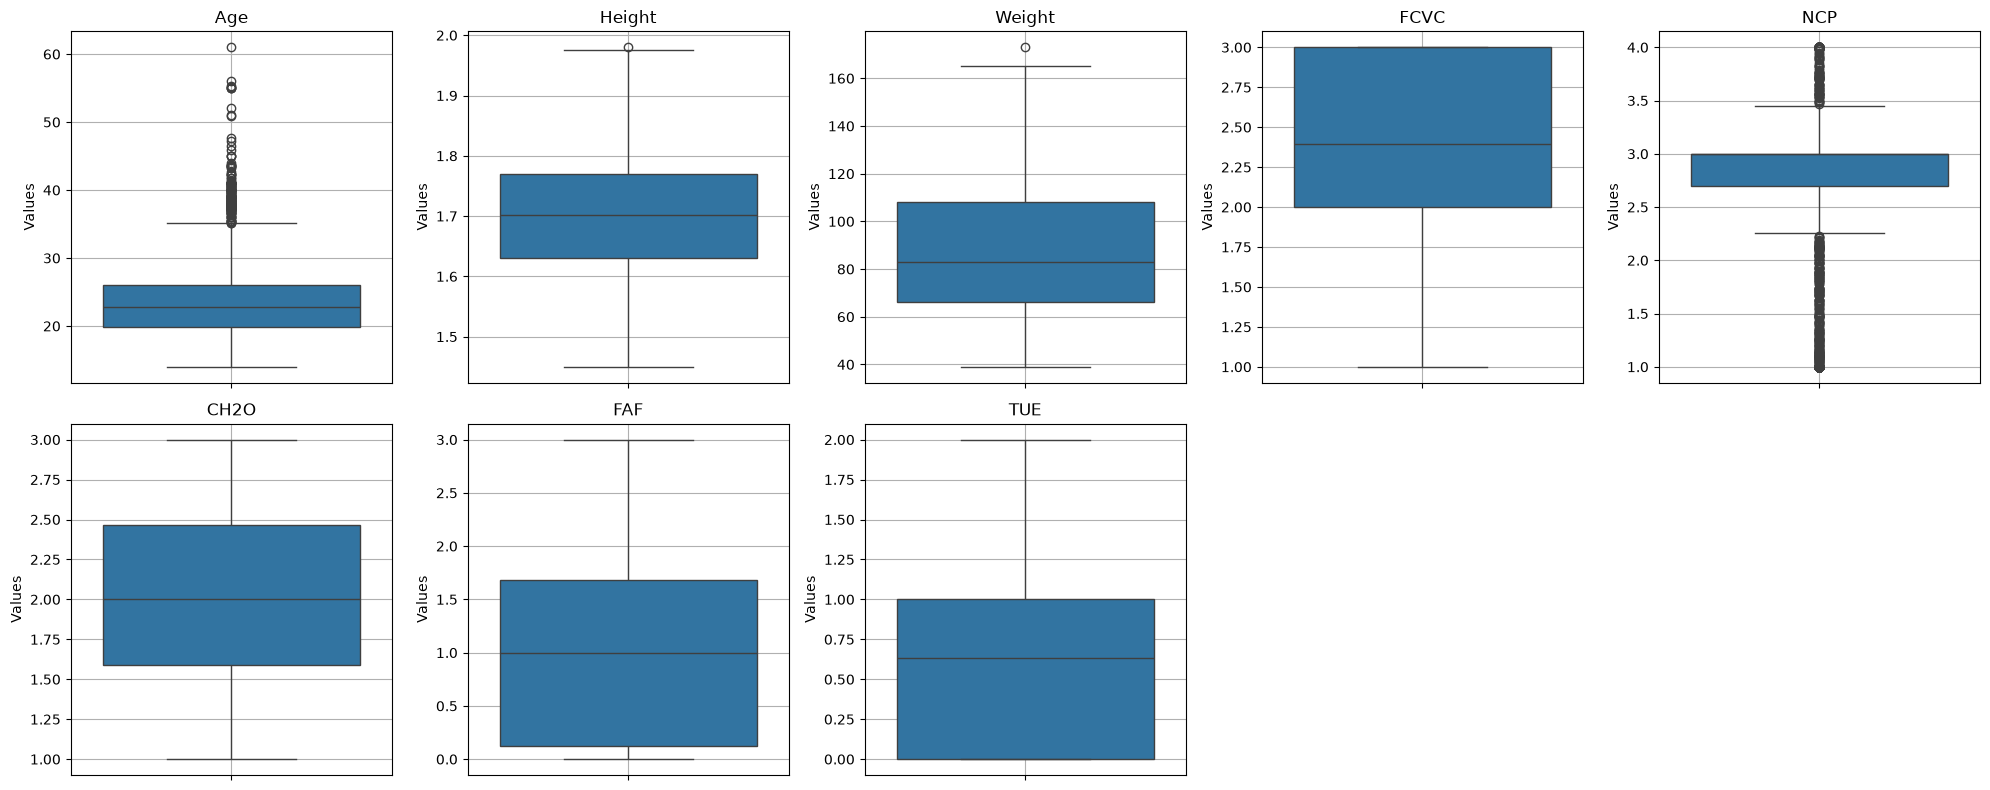

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

n_rows = 2
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

for index, feature in enumerate(numerical_features):
    sns.boxplot(data=df[feature], ax=axes[index])
    axes[index].set_title(feature)
    axes[index].set_ylabel('Values')
    axes[index].grid(True)

for i in range(len(numerical_features), len(axes)):
    plt.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [15]:
results = []

for feature in numerical_features:
    data = df[feature]
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((data < lower_bound) | (data > upper_bound)).sum()
    outliers_percentage = ((outliers / len(data)) * 100).round(2)
    results.append({'Numerical_Features' : feature, 'Outlier_Count' : outliers, 'Outliers_Percentage' : outliers_percentage})

pd.DataFrame(results)

,Numerical_Features,Outlier_Count,Outliers_Percentage
0,Age,167,8.00
1,Height,1,0.05
2,Weight,1,0.05
3,FCVC,0,0.00
4,NCP,577,27.65
5,CH2O,0,0.00
6,FAF,0,0.00
7,TUE,0,0.00


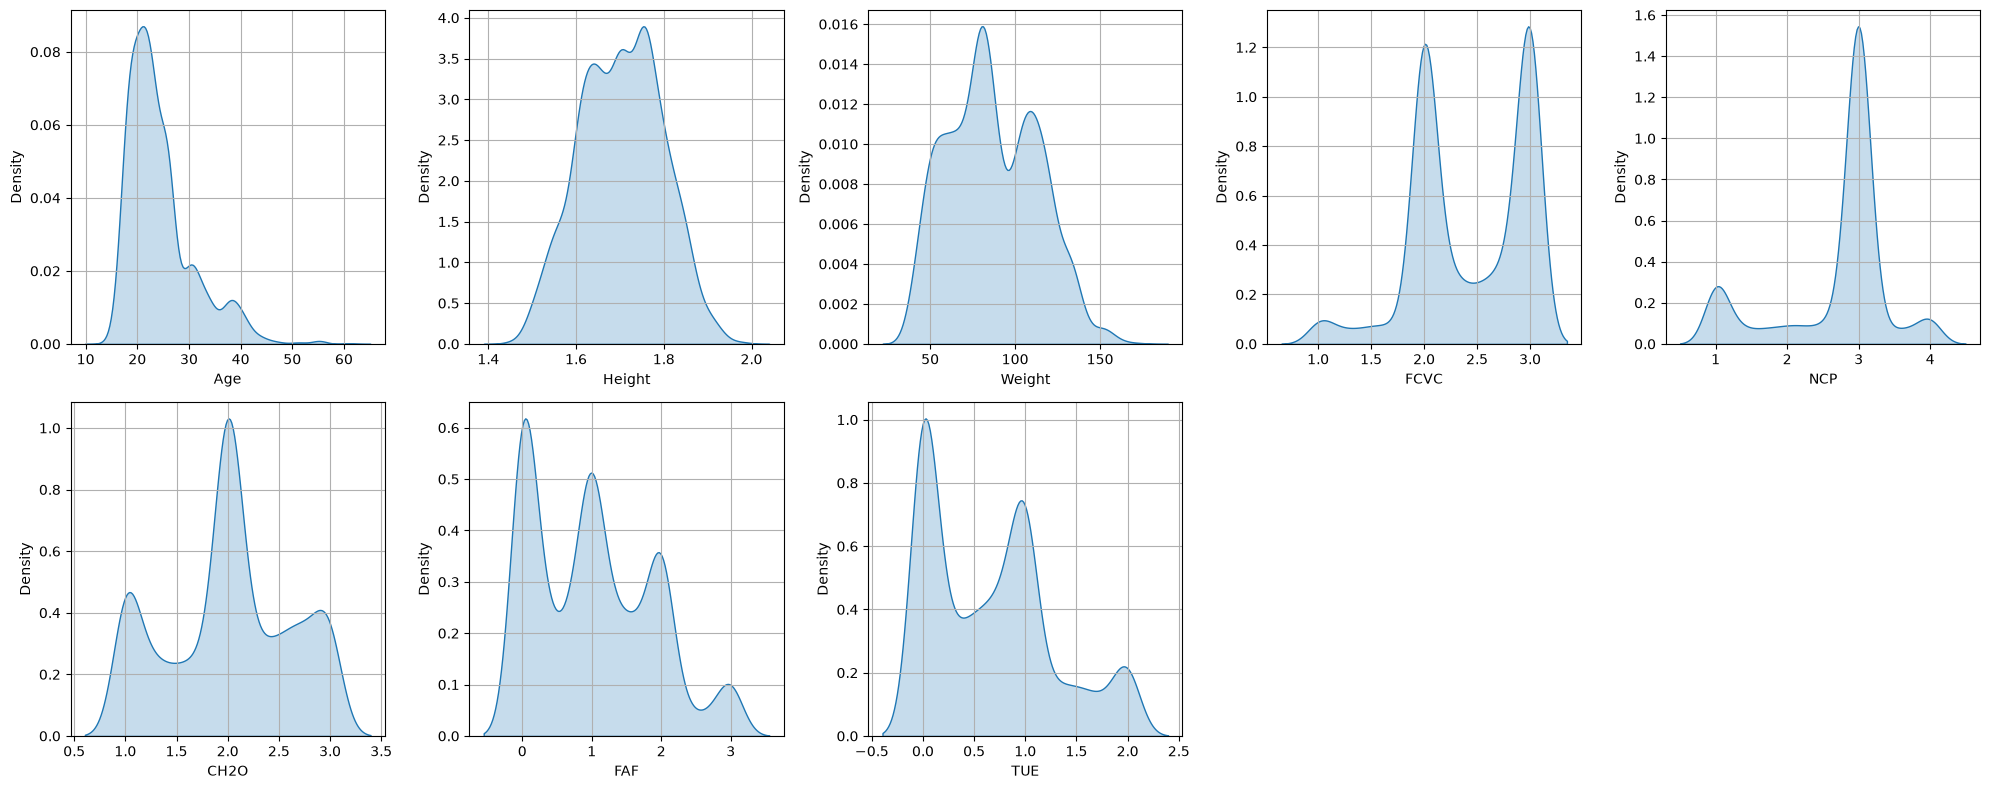

In [16]:
n_rows = 2
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten()

for index, feature in enumerate(numerical_features):
    sns.kdeplot(data=df[feature], ax=axes[index], fill=True)
    axes[index].set_ylabel('Density')
    axes[index].grid(True)

for i in range(len(numerical_features), len(axes)):
    plt.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [17]:
skewness = []

for feature in numerical_features:
    skewness.append({'Numerical_Features' : feature, 'Skewness_Value' : df[feature].skew()})

pd.DataFrame(skewness)

,Numerical_Features,Skewness_Value
0,Age,1.514305
1,Height,-0.024743
2,Weight,0.241902
3,FCVC,-0.448201
4,NCP,-1.138264
5,CH2O,-0.106330
6,FAF,0.494320
7,TUE,0.609225


In [18]:
from sklearn.model_selection import train_test_split

X = df.iloc[:, :16]
Y = df.iloc[:, 16]
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.3, random_state=42, stratify=Y)
X_test, X_val, Y_test, Y_val = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42, stratify=Y_temp)

print("Training Data Shape :", X_train.shape, Y_train.shape)
print("Validation Data Shape :", X_val.shape, Y_val.shape)
print("Testing Data Shape :", X_test.shape, Y_test.shape)

Training Data Shape : (1460, 16) (1460,)
Validation Data Shape : (314, 16) (314,)
Testing Data Shape : (313, 16) (313,)


In [19]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

oe_columns = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
ohe_columns = ["CAEC", "CALC", "MTRANS"]

oe = OrdinalEncoder()
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train[oe_columns] = oe.fit_transform(X_train[oe_columns])
X_val[oe_columns] = oe.transform(X_val[oe_columns])
X_test[oe_columns] = oe.transform(X_test[oe_columns])

X_train_ohe = pd.DataFrame(
    ohe.fit_transform(X_train[ohe_columns]),
    columns=ohe.get_feature_names_out(ohe_columns),
    index=X_train.index
)
X_val_ohe = pd.DataFrame(
    ohe.transform(X_val[ohe_columns]),
    columns=ohe.get_feature_names_out(ohe_columns),
    index=X_val.index
)
X_test_ohe = pd.DataFrame(
    ohe.transform(X_test[ohe_columns]),
    columns=ohe.get_feature_names_out(ohe_columns),
    index=X_test.index
)

X_train = pd.concat([X_train.drop(columns=ohe_columns), X_train_ohe], axis=1)
X_val = pd.concat([X_val.drop(columns=ohe_columns), X_val_ohe], axis=1)
X_test = pd.concat([X_test.drop(columns=ohe_columns), X_test_ohe], axis=1)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (1460, 26)
Validation shape: (314, 26)
Testing shape: (313, 26)


In [20]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}

for model_name, model in models.items():
    model.fit(X_train, Y_train)
    print(f"{model_name} training completed.")

Random Forest training completed.
Extra Trees training completed.


In [21]:
from sklearn.metrics import accuracy_score, f1_score

datasets = {
    "Train": (X_train, Y_train),
    "Validation": (X_val, Y_val),
    "Test": (X_test, Y_test)
}

performance_results = []

for model_name, model in models.items():
    for split_name, (X_split, Y_split) in datasets.items():
        Y_pred = model.predict(X_split)

        performance_results.append({
            "Model": model_name,
            "Dataset": split_name,
            "Accuracy": accuracy_score(Y_split, Y_pred),
            "Macro-F1": f1_score(Y_split, Y_pred, average="macro")
        })

performance_df = pd.DataFrame(performance_results)

display(
    performance_df.style
    .format({
        "Accuracy": "{:.4f}",
        "Macro-F1": "{:.4f}"
    })
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]}
    ])
)

,Model,Dataset,Accuracy,Macro-F1
0,Random Forest,Train,1.0000,1.0000
1,Random Forest,Validation,0.9427,0.9414
2,Random Forest,Test,0.9521,0.9515
3,Extra Trees,Train,1.0000,1.0000
4,Extra Trees,Validation,0.9299,0.9276
5,Extra Trees,Test,0.8978,0.8972


In [22]:
X_train.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CAEC_Always', 'CAEC_Frequently', 'CAEC_Sometimes', 'CAEC_no',
       'CALC_Always', 'CALC_Frequently', 'CALC_Sometimes', 'CALC_no',
       'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike',
       'MTRANS_Public_Transportation', 'MTRANS_Walking'],
      dtype='str')

In [23]:
import numpy as np
import shap
from scipy.sparse import issparse

feature_names = X_train.columns.tolist()

X_test_array = X_test.toarray() if issparse(X_test) else np.asarray(X_test)
X_test = pd.DataFrame(X_test_array, columns=feature_names)

def calculate_shap_importance(model, X_data):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_data)

    # Handle multiclass SHAP output
    if isinstance(shap_values, list):
        shap_values = np.stack(shap_values, axis=-1)
    else:
        shap_values = np.asarray(shap_values)

    # Average absolute SHAP values across samples and classes
    if shap_values.ndim == 3:
        importance = np.abs(shap_values).mean(axis=(0, 2))
    else:
        importance = np.abs(shap_values).mean(axis=0)

    return pd.Series(
        importance,
        index=X_data.columns
    ).sort_values(ascending=False)

rf_shap = calculate_shap_importance(
    models["Random Forest"], X_test
)
et_shap = calculate_shap_importance(
    models["Extra Trees"], X_test
)

pd.DataFrame({
    "Random Forest": rf_shap,
    "Extra Trees": et_shap
}).fillna(0).round(4)

,Random Forest,Extra Trees
Age,0.0237,0.0158
CAEC_Always,0.0008,0.0017
CAEC_Frequently,0.0090,0.0108
CAEC_Sometimes,0.0088,0.0133
CAEC_no,0.0007,0.0013
CALC_Always,0.0000,0.0000
CALC_Frequently,0.0007,0.0014
CALC_Sometimes,0.0091,0.0185
CALC_no,0.0097,0.0148
CH2O,0.0087,0.0078


In [24]:
def group_feature_importance(importance):
    grouped = {}

    for feature, value in importance.items():
        if feature.startswith("CAEC_"):
            original_feature = "CAEC"
        elif feature.startswith("CALC_"):
            original_feature = "CALC"
        elif feature.startswith("MTRANS_"):
            original_feature = "MTRANS"
        else:
            original_feature = feature

        grouped[original_feature] = (
            grouped.get(original_feature, 0) + value
        )

    return pd.Series(grouped).sort_values(ascending=False)

rf_grouped = group_feature_importance(rf_shap)
et_grouped = group_feature_importance(et_shap)

pd.DataFrame({
    "Random Forest": rf_grouped,
    "Extra Trees": et_grouped
}).fillna(0).round(4)

,Random Forest,Extra Trees
Age,0.0237,0.0158
CAEC,0.0194,0.0271
CALC,0.0196,0.0347
CH2O,0.0087,0.0078
FAF,0.0079,0.0071
FAVC,0.0060,0.0110
FCVC,0.0288,0.0198
Gender,0.0256,0.0417
Height,0.0192,0.0127
MTRANS,0.0074,0.0201


In [25]:
rf_top5 = set(rf_grouped.nlargest(5).index)
et_top5 = set(et_grouped.nlargest(5).index)

common_features = rf_top5 & et_top5
top5_overlap = len(common_features) / 5 * 100

print("Random Forest Top 5:", list(rf_grouped.nlargest(5).index))
print("Extra Trees Top 5:", list(et_grouped.nlargest(5).index))
print("Common Top 5:", sorted(common_features))
print(f"Top-5 Feature Overlap: {top5_overlap:.2f}%")

Random Forest Top 5: ['Weight', 'FCVC', 'Gender', 'Age', 'CALC']
Extra Trees Top 5: ['Weight', 'Gender', 'CALC', 'CAEC', 'family_history_with_overweight']
Common Top 5: ['CALC', 'Gender', 'Weight']
Top-5 Feature Overlap: 60.00%


In [26]:
from scipy.stats import spearmanr

all_features = sorted(set(rf_grouped.index) | set(et_grouped.index))

rf_values = rf_grouped.reindex(all_features).fillna(0)
et_values = et_grouped.reindex(all_features).fillna(0)

correlation, p_value = spearmanr(rf_values, et_values)

print(f"Spearman Rank Correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

Spearman Rank Correlation: 0.8029
P-value: 0.000181


In [28]:
# Use the exact feature order used to train the models
feature_names = X_train.columns.tolist()
X_test_array = X_test.toarray() if issparse(X_test) else np.asarray(X_test)
X_test = pd.DataFrame(X_test_array, columns=feature_names)

# Map encoded columns to their original feature names
def original_feature_name(name):
    for prefix in ["CAEC_", "CALC_", "MTRANS_"]:
        if name.startswith(prefix):
            return prefix[:-1]
    return name

feature_groups = {}
for i, name in enumerate(feature_names):
    original = original_feature_name(name)
    feature_groups.setdefault(original, []).append(i)

def calculate_grouped_shap(model, X_data):
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X_data)

    if isinstance(values, list):
        # Older SHAP versions: one array per class
        values = np.stack(values, axis=-1)
    else:
        values = np.asarray(values)

    if values.ndim == 2:
        values = values[:, :, np.newaxis]

    # Sum encoded-column contributions first, then take absolute values
    grouped_importance = {}
    for feature, indices in feature_groups.items():
        grouped_values = values[:, indices, :].sum(axis=1)
        grouped_importance[feature] = np.abs(grouped_values).mean()

    return pd.Series(grouped_importance).sort_values(ascending=False)

rf_grouped = calculate_grouped_shap(
    models["Random Forest"], X_test
)
et_grouped = calculate_grouped_shap(
    models["Extra Trees"], X_test
)

grouped_comparison = pd.DataFrame({
    "Random Forest": rf_grouped,
    "Extra Trees": et_grouped
}).fillna(0)

display(grouped_comparison.sort_values(
    "Random Forest", ascending=False
).round(4))

,Random Forest,Extra Trees
Weight,0.0931,0.0746
FCVC,0.0288,0.0198
Gender,0.0256,0.0417
Age,0.0237,0.0158
Height,0.0192,0.0127
CALC,0.0186,0.0326
CAEC,0.0178,0.0240
family_history_with_overweight,0.0176,0.0258
NCP,0.0130,0.0114
TUE,0.0099,0.0081


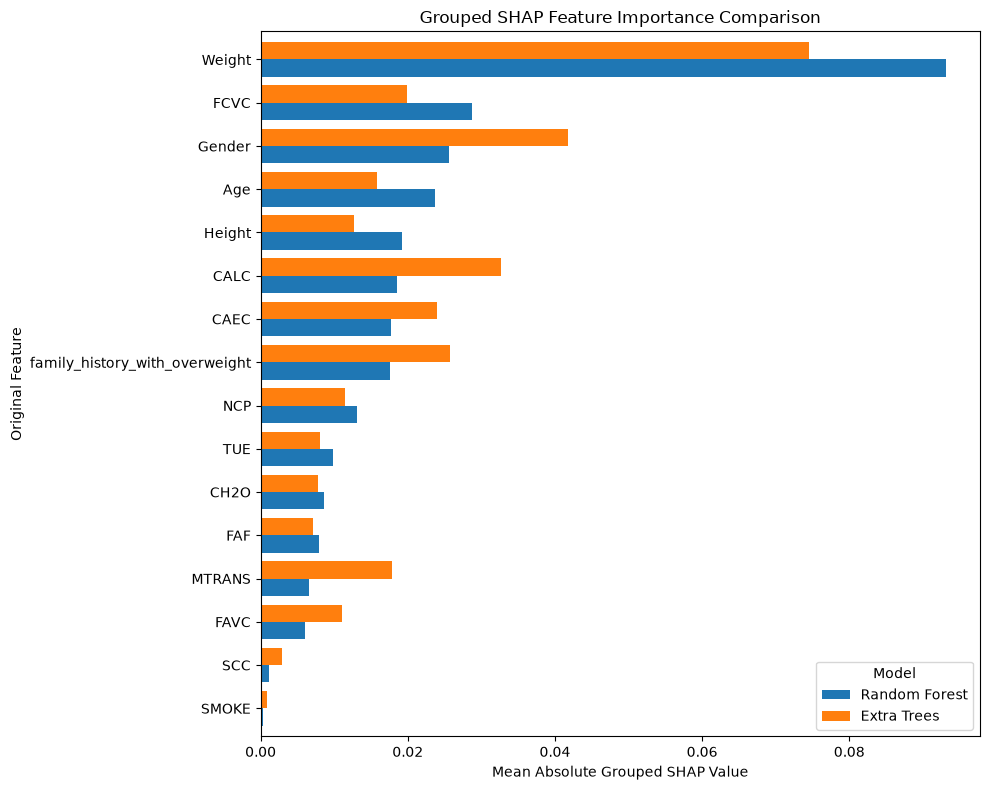

In [29]:
plot_df = grouped_comparison.sort_values(
    "Random Forest", ascending=True
)

ax = plot_df.plot(
    kind="barh",
    figsize=(10, 8),
    width=0.8
)

ax.set_title("Grouped SHAP Feature Importance Comparison")
ax.set_xlabel("Mean Absolute Grouped SHAP Value")
ax.set_ylabel("Original Feature")
ax.legend(title="Model")
plt.tight_layout()
plt.show()

In [30]:
rf_top5 = set(rf_grouped.nlargest(5).index)
et_top5 = set(et_grouped.nlargest(5).index)
common_features = rf_top5 & et_top5

top5_overlap = len(common_features) / 5 * 100

all_features = sorted(
    set(rf_grouped.index) | set(et_grouped.index)
)
rf_ranks = rf_grouped.reindex(all_features).fillna(0).rank(
    ascending=False, method="average"
)
et_ranks = et_grouped.reindex(all_features).fillna(0).rank(
    ascending=False, method="average"
)

correlation, p_value = spearmanr(rf_ranks, et_ranks)

print("Random Forest Top 5:", list(rf_grouped.nlargest(5).index))
print("Extra Trees Top 5:", list(et_grouped.nlargest(5).index))
print("Common Top 5:", sorted(common_features))
print(f"Top-5 Feature Overlap: {top5_overlap:.2f}%")
print(f"Spearman Rank Correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

Random Forest Top 5: ['Weight', 'FCVC', 'Gender', 'Age', 'Height']
Extra Trees Top 5: ['Weight', 'Gender', 'CALC', 'family_history_with_overweight', 'CAEC']
Common Top 5: ['Gender', 'Weight']
Top-5 Feature Overlap: 40.00%
Spearman Rank Correlation: 0.8000
P-value: 0.000199


In [ ]:
final_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Test Accuracy": 0.9521,
        "Test Macro-F1": 0.9515,
        "Top-5 Overlap (%)": top5_overlap,
        "Spearman Correlation": correlation
    },
    {
        "Model": "Extra Trees",
        "Test Accuracy": 0.8978,
        "Test Macro-F1": 0.8972,
        "Top-5 Overlap (%)": top5_overlap,
        "Spearman Correlation": correlation
    }
])

final_results.round(4)

,Model,Test Accuracy,Test Macro-F1,Top-5 Overlap (%),Spearman Correlation
0,Random Forest,0.9521,0.9515,40.0,0.8
1,Extra Trees,0.8978,0.8972,40.0,0.8
